In [1]:
import numpy as np
import pandas as pd
import sklearn
import shap

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SHAP:", shap.__version__)

C:\Users\ASUS\anaconda3\envs\realestate\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NumPy: 1.26.4
Pandas: 2.2.3
Scikit-learn: 1.5.2
SHAP: 0.46.0


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
pd.set_option('display.max_columns', None)

In [7]:
df = pd.read_csv('gurgaon_properties_missing_value_imputation.csv')

In [9]:
df.shape

(3544, 18)

In [11]:
df.head()

,property_type,society,sector,price,price_per_sqft,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,flat,adani oyster greens,sector 102,1.90,10058.0,3.0,3.0,3+,9.0,Relatively New,2099.0,1,0,1,1,0,0,0
1,flat,ramprastha city,dwarka expressway,1.30,9027.0,3.0,3.0,2,3.0,Under Construction,1303.0,0,0,0,0,0,0,0
2,flat,assotech blith,sector 99,0.92,6739.0,2.0,2.0,3+,22.0,Under Construction,1235.0,0,0,0,0,0,0,56
3,flat,aipl the peaceful homes,sector 70a,2.80,11914.0,3.0,4.0,3,22.0,Relatively New,2350.0,0,1,0,0,0,0,49
4,flat,gls avenue 51,sector 92,0.42,7106.0,2.0,2.0,1,4.0,Relatively New,657.0,1,0,0,1,0,2,42


In [13]:
train_df = df.drop(columns=['society','price_per_sqft'])

In [15]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,flat,sector 102,1.90,3.0,3.0,3+,9.0,Relatively New,2099.0,1,0,1,1,0,0,0
1,flat,dwarka expressway,1.30,3.0,3.0,2,3.0,Under Construction,1303.0,0,0,0,0,0,0,0
2,flat,sector 99,0.92,2.0,2.0,3+,22.0,Under Construction,1235.0,0,0,0,0,0,0,56
3,flat,sector 70a,2.80,3.0,4.0,3,22.0,Relatively New,2350.0,0,1,0,0,0,0,49
4,flat,sector 92,0.42,2.0,2.0,1,4.0,Relatively New,657.0,1,0,0,1,0,2,42


luxury score

<Axes: ylabel='luxury_score'>

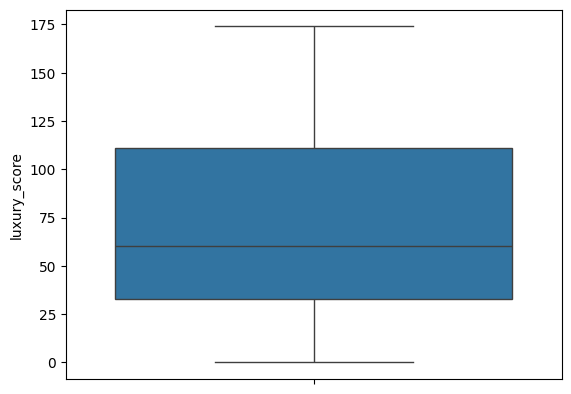

In [21]:
sns.boxplot(df['luxury_score'])

In [23]:
def categorize_luxury(score):
    if 0 <= score < 50:
        return "Low"
    elif 50 <= score < 150:
        return "Medium"
    elif 150 <= score <= 175:
        return "High"
    else:
        return None  # or "Undefined" or any other label for scores outside the defined bins

In [25]:
train_df['luxury_category'] = train_df['luxury_score'].apply(categorize_luxury)

In [27]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score,luxury_category
0,flat,sector 102,1.90,3.0,3.0,3+,9.0,Relatively New,2099.0,1,0,1,1,0,0,0,Low
1,flat,dwarka expressway,1.30,3.0,3.0,2,3.0,Under Construction,1303.0,0,0,0,0,0,0,0,Low
2,flat,sector 99,0.92,2.0,2.0,3+,22.0,Under Construction,1235.0,0,0,0,0,0,0,56,Medium
3,flat,sector 70a,2.80,3.0,4.0,3,22.0,Relatively New,2350.0,0,1,0,0,0,0,49,Low
4,flat,sector 92,0.42,2.0,2.0,1,4.0,Relatively New,657.0,1,0,0,1,0,2,42,Low


floorNum

<Axes: ylabel='floorNum'>

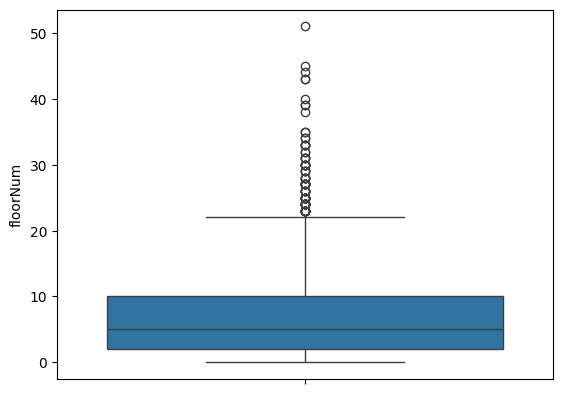

In [33]:
sns.boxplot(df['floorNum'])

In [35]:
def categorize_floor(floor):
    if 0 <= floor <= 2:
        return "Low Floor"
    elif 3 <= floor <= 10:
        return "Mid Floor"
    elif 11 <= floor <= 51:
        return "High Floor"
    else:
        return None  # or "Undefined" or any other label for floors outside the defined bins

In [37]:
train_df['floor_category'] = train_df['floorNum'].apply(categorize_floor)

In [39]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score,luxury_category,floor_category
0,flat,sector 102,1.90,3.0,3.0,3+,9.0,Relatively New,2099.0,1,0,1,1,0,0,0,Low,Mid Floor
1,flat,dwarka expressway,1.30,3.0,3.0,2,3.0,Under Construction,1303.0,0,0,0,0,0,0,0,Low,Mid Floor
2,flat,sector 99,0.92,2.0,2.0,3+,22.0,Under Construction,1235.0,0,0,0,0,0,0,56,Medium,High Floor
3,flat,sector 70a,2.80,3.0,4.0,3,22.0,Relatively New,2350.0,0,1,0,0,0,0,49,Low,High Floor
4,flat,sector 92,0.42,2.0,2.0,1,4.0,Relatively New,657.0,1,0,0,1,0,2,42,Low,Mid Floor


In [41]:
train_df.drop(columns=['floorNum','luxury_score'],inplace=True)

In [43]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_category,floor_category
0,flat,sector 102,1.90,3.0,3.0,3+,Relatively New,2099.0,1,0,1,1,0,0,Low,Mid Floor
1,flat,dwarka expressway,1.30,3.0,3.0,2,Under Construction,1303.0,0,0,0,0,0,0,Low,Mid Floor
2,flat,sector 99,0.92,2.0,2.0,3+,Under Construction,1235.0,0,0,0,0,0,0,Medium,High Floor
3,flat,sector 70a,2.80,3.0,4.0,3,Relatively New,2350.0,0,1,0,0,0,0,Low,High Floor
4,flat,sector 92,0.42,2.0,2.0,1,Relatively New,657.0,1,0,0,1,0,2,Low,Mid Floor


In [45]:
from sklearn.preprocessing import OrdinalEncoder

# Create a copy of the original data for label encoding
data_label_encoded = train_df.copy()

categorical_cols = train_df.select_dtypes(include=['object']).columns

# Apply label encoding to categorical columns
for col in categorical_cols:
    oe = OrdinalEncoder()
    data_label_encoded[col] = oe.fit_transform(data_label_encoded[[col]])
    print(oe.categories_)

# Splitting the dataset into training and testing sets
X_label = data_label_encoded.drop('price', axis=1)
y_label = data_label_encoded['price']

[array(['flat', 'house'], dtype=object)]
[array(['dwarka expressway', 'gwal pahari', 'manesar', 'new',
       'new sector 2', 'sector 1', 'sector 102', 'sector 103',
       'sector 104', 'sector 105', 'sector 106', 'sector 107',
       'sector 108', 'sector 109', 'sector 10a', 'sector 11',
       'sector 110', 'sector 111', 'sector 112', 'sector 113',
       'sector 12', 'sector 13', 'sector 14', 'sector 15', 'sector 17',
       'sector 17a', 'sector 17b', 'sector 2', 'sector 21', 'sector 22',
       'sector 23', 'sector 24', 'sector 25', 'sector 26', 'sector 27',
       'sector 28', 'sector 3', 'sector 3 phase 2',
       'sector 3 phase 3 extension', 'sector 30', 'sector 31',
       'sector 33', 'sector 36', 'sector 36a', 'sector 37', 'sector 37c',
       'sector 37d', 'sector 38', 'sector 39', 'sector 4', 'sector 40',
       'sector 41', 'sector 43', 'sector 45', 'sector 46', 'sector 47',
       'sector 48', 'sector 49', 'sector 5', 'sector 50', 'sector 51',
       'sector 52', 'sect

In [47]:
X_label

,property_type,sector,bedRoom,bathroom,balcony,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_category,floor_category
0,0.0,6.0,3.0,3.0,4.0,3.0,2099.0,1,0,1,1,0,0,1.0,2.0
1,0.0,0.0,3.0,3.0,2.0,4.0,1303.0,0,0,0,0,0,0,1.0,2.0
2,0.0,110.0,2.0,2.0,4.0,4.0,1235.0,0,0,0,0,0,0,2.0,0.0
3,0.0,83.0,3.0,4.0,3.0,3.0,2350.0,0,1,0,0,0,0,1.0,0.0
4,0.0,107.0,2.0,2.0,1.0,3.0,657.0,1,0,0,1,0,2,1.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3539,0.0,97.0,2.0,2.0,2.0,3.0,950.0,0,0,0,0,0,2,0.0,1.0
3540,0.0,35.0,2.0,1.0,1.0,2.0,1188.0,0,0,0,0,0,0,2.0,1.0
3541,0.0,80.0,3.0,3.0,2.0,3.0,1428.0,0,0,0,1,0,2,0.0,2.0
3542,0.0,85.0,3.0,4.0,4.0,0.0,2185.0,0,1,0,0,0,0,1.0,2.0


In [49]:
y_label

0       1.90
1       1.30
2       0.92
3       2.80
4       0.42
        ... 
3539    0.65
3540    0.95
3541    1.52
3542    3.40
3543    2.80
Name: price, Length: 3544, dtype: float64

Technique 1 - Correlation Analysis

<Axes: >

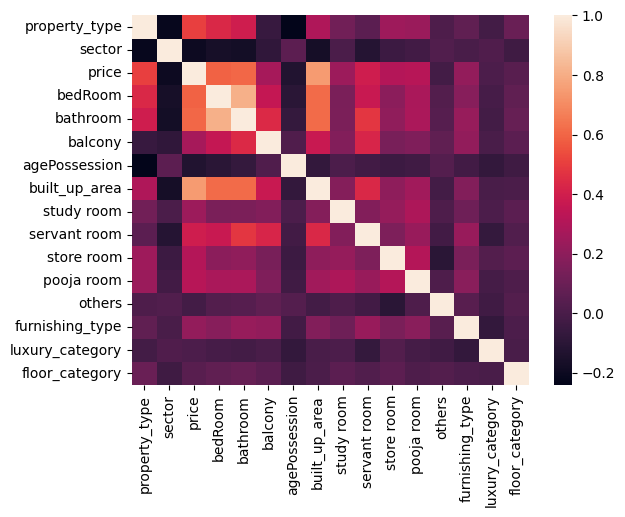

In [54]:
sns.heatmap(data_label_encoded.corr())

In [56]:
fi_df1 = data_label_encoded.corr()['price'].iloc[1:].to_frame().reset_index().rename(columns={'index':'feature','price':'corr_coeff'})
fi_df1

,feature,corr_coeff
0,sector,-0.199875
1,price,1.000000
2,bedRoom,0.590159
3,bathroom,0.606751
4,balcony,0.270181
5,agePossession,-0.132677
6,built_up_area,0.745165
7,study room,0.242332
8,servant room,0.392262
9,store room,0.309877


Technique 2 - Random Forest Feature Importance

In [61]:
from sklearn.ensemble import RandomForestRegressor

# Train a Random Forest regressor on label encoded data
rf_label = RandomForestRegressor(n_estimators=100, random_state=42)
rf_label.fit(X_label, y_label)

# Extract feature importance scores for label encoded data
fi_df2 = pd.DataFrame({
    'feature': X_label.columns,
    'rf_importance': rf_label.feature_importances_
}).sort_values(by='rf_importance', ascending=False)

fi_df2

,feature,rf_importance
6,built_up_area,0.642904
0,property_type,0.109869
1,sector,0.109237
3,bathroom,0.027423
2,bedRoom,0.021380
8,servant room,0.018990
5,agePossession,0.016411
4,balcony,0.013823
9,store room,0.007774
12,furnishing_type,0.007220


Technique 3 - Gradient Boosting Feature importances

In [66]:
from sklearn.ensemble import GradientBoostingRegressor

# Train a Random Forest regressor on label encoded data
gb_label = GradientBoostingRegressor()
gb_label.fit(X_label, y_label)

# Extract feature importance scores for label encoded data
fi_df3 = pd.DataFrame({
    'feature': X_label.columns,
    'gb_importance': gb_label.feature_importances_
}).sort_values(by='gb_importance', ascending=False)

fi_df3

,feature,gb_importance
6,built_up_area,0.669923
1,sector,0.107588
0,property_type,0.100941
3,bathroom,0.039745
2,bedRoom,0.036535
8,servant room,0.021776
9,store room,0.011575
5,agePossession,0.004807
4,balcony,0.002644
13,luxury_category,0.001595


Technique 4 - Permutation Importance

In [71]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

X_train_label, X_test_label, y_train_label, y_test_label = train_test_split(X_label, y_label, test_size=0.2, random_state=42)

# Train a Random Forest regressor on label encoded data
rf_label = RandomForestRegressor(n_estimators=100, random_state=42)
rf_label.fit(X_train_label, y_train_label)

# Calculate Permutation Importance
perm_importance = permutation_importance(rf_label, X_test_label, y_test_label, n_repeats=30, random_state=42)

# Organize results into a DataFrame
fi_df4 = pd.DataFrame({
    'feature': X_label.columns,
    'permutation_importance': perm_importance.importances_mean
}).sort_values(by='permutation_importance', ascending=False)

fi_df4

,feature,permutation_importance
6,built_up_area,0.747739
0,property_type,0.203817
1,sector,0.184733
2,bedRoom,0.008172
3,bathroom,0.007829
8,servant room,0.007414
5,agePossession,0.004888
4,balcony,0.001994
13,luxury_category,0.001973
11,others,0.000910


Technique 5 - LASSO

In [76]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_label)

# Train a LASSO regression model
# We'll use a relatively small value for alpha (the regularization strength) for demonstration purposes
lasso = Lasso(alpha=0.01, random_state=42)
lasso.fit(X_scaled, y_label)

# Extract coefficients
fi_df5 = pd.DataFrame({
    'feature': X_label.columns,
    'lasso_coeff': lasso.coef_
}).sort_values(by='lasso_coeff', ascending=False)

fi_df5

,feature,lasso_coeff
6,built_up_area,1.464869
0,property_type,0.688819
3,bathroom,0.295926
9,store room,0.204440
7,study room,0.169036
8,servant room,0.155962
12,furnishing_type,0.134179
10,pooja room,0.070989
13,luxury_category,0.050693
2,bedRoom,0.000000


Technique 6 - RFE

In [81]:
from sklearn.feature_selection import RFE

# Initialize the base estimator
estimator = RandomForestRegressor()

# Apply RFE on the label-encoded and standardized training data
selector_label = RFE(estimator, n_features_to_select=X_label.shape[1], step=1)
selector_label = selector_label.fit(X_label, y_label)

# Get the selected features based on RFE
selected_features = X_label.columns[selector_label.support_]

# Extract the coefficients for the selected features from the underlying linear regression model
selected_coefficients = selector_label.estimator_.feature_importances_

# Organize the results into a DataFrame
fi_df6 = pd.DataFrame({
    'feature': selected_features,
    'rfe_score': selected_coefficients
}).sort_values(by='rfe_score', ascending=False)

fi_df6

,feature,rfe_score
6,built_up_area,0.641774
0,property_type,0.111409
1,sector,0.106024
3,bathroom,0.027241
8,servant room,0.022691
2,bedRoom,0.022571
5,agePossession,0.014124
4,balcony,0.013767
13,luxury_category,0.009220
9,store room,0.007647


Technique 7 - Linear Regression Weights

In [86]:
from sklearn.linear_model import LinearRegression

In [87]:
# Train a linear regression model on the label-encoded and standardized training data
lin_reg = LinearRegression()
lin_reg.fit(X_scaled, y_label)

# Extract coefficients
fi_df7 = pd.DataFrame({
    'feature': X_label.columns,
    'reg_coeffs': lin_reg.coef_
}).sort_values(by='reg_coeffs', ascending=False)

fi_df7

,feature,reg_coeffs
6,built_up_area,1.467845
0,property_type,0.686870
3,bathroom,0.306235
9,store room,0.208976
7,study room,0.177511
8,servant room,0.164799
12,furnishing_type,0.143339
10,pooja room,0.074133
13,luxury_category,0.061376
2,bedRoom,-0.001497


Technique 8 - SHAP

In [91]:
!pip install shap

import shap
import numpy as np
from sklearn.ensemble import RandomForestRegressor

# Train Random Forest
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf.fit(X_label, y_label)

# Create SHAP explainer
explainer = shap.TreeExplainer(rf)

# Calculate SHAP values
shap_values = explainer.shap_values(X_label)

# Overall feature importance
shap_sum = np.abs(shap_values).mean(axis=0)

# Display SHAP values
shap_values

array([[-0.53345741, -0.08527767, -0.02331044, ...,  0.00345418,
        -0.01067323, -0.02000882],
       [-0.21473779, -0.22165402, -0.01915024, ..., -0.00605001,
        -0.00703101, -0.02280789],
       [-0.19287884, -0.44050742, -0.04084662, ..., -0.00936402,
         0.00347652,  0.02718161],
       ...,
       [-0.21912135,  0.01400053, -0.01492166, ...,  0.00809287,
         0.02668776,  0.01414305],
       [-0.43285131,  0.24876482,  0.01177847, ..., -0.00690646,
         0.03110652, -0.00564199],
       [-0.29441583,  0.5468978 , -0.01311126, ...,  0.00444433,
         0.00796036, -0.033612  ]])

In [92]:
shap_importance = pd.DataFrame({
    'feature': X_label.columns,
    'SHAP_importance': shap_sum
}).sort_values(
    by='SHAP_importance',
    ascending=False
)

shap_importance

,feature,SHAP_importance
6,built_up_area,1.219966
0,property_type,0.480008
1,sector,0.382771
3,bathroom,0.119536
8,servant room,0.091794
2,bedRoom,0.053064
4,balcony,0.041898
5,agePossession,0.025698
14,floor_category,0.025079
12,furnishing_type,0.019739


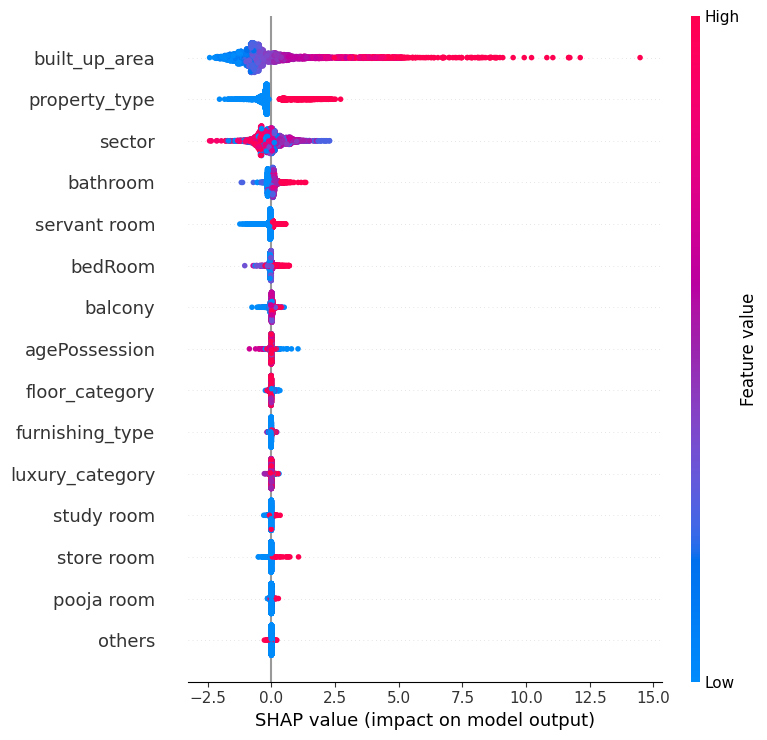

In [93]:
shap.summary_plot(shap_values, X_label)

In [98]:
fi_df8 = pd.DataFrame({
    'feature': X_label.columns,
    'SHAP_score': np.abs(shap_values).mean(axis=0)
}).sort_values(by='SHAP_score', ascending=False)

fi_df8

,feature,SHAP_score
6,built_up_area,1.219966
0,property_type,0.480008
1,sector,0.382771
3,bathroom,0.119536
8,servant room,0.091794
2,bedRoom,0.053064
4,balcony,0.041898
5,agePossession,0.025698
14,floor_category,0.025079
12,furnishing_type,0.019739


In [100]:
final_fi_df = fi_df1.merge(fi_df2,on='feature').merge(fi_df3,on='feature').merge(fi_df4,on='feature').merge(fi_df5,on='feature').merge(fi_df6,on='feature').merge(fi_df7,on='feature').merge(fi_df8,on='feature').set_index('feature')

In [102]:
final_fi_df

,corr_coeff,rf_importance,gb_importance,permutation_importance,lasso_coeff,rfe_score,reg_coeffs,SHAP_score
feature,,,,,,,,
sector,-0.199875,0.109237,0.107588,0.184733,-0.055625,0.106024,-0.064579,0.382771
bedRoom,0.590159,0.021380,0.036535,0.008172,0.000000,0.022571,-0.001497,0.053064
bathroom,0.606751,0.027423,0.039745,0.007829,0.295926,0.027241,0.306235,0.119536
balcony,0.270181,0.013823,0.002644,0.001994,-0.055615,0.013767,-0.078632,0.041898
agePossession,-0.132677,0.016411,0.004807,0.004888,-0.031922,0.014124,-0.039429,0.025698
built_up_area,0.745165,0.642904,0.669923,0.747739,1.464869,0.641774,1.467845,1.219966
study room,0.242332,0.005036,0.000915,-0.002656,0.169036,0.005101,0.177511,0.015238
servant room,0.392262,0.018990,0.021776,0.007414,0.155962,0.022691,0.164799,0.091794
store room,0.309877,0.007774,0.011575,-0.002509,0.204440,0.007647,0.208976,0.014556


In [104]:
# normalize the score
final_fi_df = final_fi_df.divide(final_fi_df.sum(axis=0), axis=1)

In [106]:
final_fi_df[['rf_importance','gb_importance','permutation_importance','rfe_score','SHAP_score']].mean(axis=1).sort_values(ascending=False)

feature
built_up_area      0.713506
sector             0.148394
bathroom           0.034477
bedRoom            0.024915
servant room       0.024757
agePossession      0.011473
balcony            0.011313
store room         0.006945
luxury_category    0.006002
floor_category     0.005271
furnishing_type    0.005103
study room         0.003421
pooja room         0.002355
others             0.002069
dtype: float64

In [108]:
# to drop pooja room, study room, others
X_label

,property_type,sector,bedRoom,bathroom,balcony,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_category,floor_category
0,0.0,6.0,3.0,3.0,4.0,3.0,2099.0,1,0,1,1,0,0,1.0,2.0
1,0.0,0.0,3.0,3.0,2.0,4.0,1303.0,0,0,0,0,0,0,1.0,2.0
2,0.0,110.0,2.0,2.0,4.0,4.0,1235.0,0,0,0,0,0,0,2.0,0.0
3,0.0,83.0,3.0,4.0,3.0,3.0,2350.0,0,1,0,0,0,0,1.0,0.0
4,0.0,107.0,2.0,2.0,1.0,3.0,657.0,1,0,0,1,0,2,1.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3539,0.0,97.0,2.0,2.0,2.0,3.0,950.0,0,0,0,0,0,2,0.0,1.0
3540,0.0,35.0,2.0,1.0,1.0,2.0,1188.0,0,0,0,0,0,0,2.0,1.0
3541,0.0,80.0,3.0,3.0,2.0,3.0,1428.0,0,0,0,1,0,2,0.0,2.0
3542,0.0,85.0,3.0,4.0,4.0,0.0,2185.0,0,1,0,0,0,0,1.0,2.0


In [110]:
# with all the cols
from sklearn.model_selection import cross_val_score

rf = RandomForestRegressor(n_estimators=100, random_state=42)

scores = cross_val_score(rf, X_label, y_label, cv=5, scoring='r2')

In [112]:
scores.mean()

0.8120019572624958

In [114]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)

scores = cross_val_score(rf, X_label.drop(columns=['pooja room', 'study room', 'others']), y_label, cv=5, scoring='r2')

In [116]:
scores.mean()

0.8109349207900948

In [118]:
export_df = X_label.drop(columns=['pooja room', 'study room', 'others'])
export_df['price'] = y_label

In [120]:
export_df.to_csv('gurgaon_properties_post_feature_selection.csv', index=False)

In [122]:
export_df

,property_type,sector,bedRoom,bathroom,balcony,agePossession,built_up_area,servant room,store room,furnishing_type,luxury_category,floor_category,price
0,0.0,6.0,3.0,3.0,4.0,3.0,2099.0,0,1,0,1.0,2.0,1.90
1,0.0,0.0,3.0,3.0,2.0,4.0,1303.0,0,0,0,1.0,2.0,1.30
2,0.0,110.0,2.0,2.0,4.0,4.0,1235.0,0,0,0,2.0,0.0,0.92
3,0.0,83.0,3.0,4.0,3.0,3.0,2350.0,1,0,0,1.0,0.0,2.80
4,0.0,107.0,2.0,2.0,1.0,3.0,657.0,0,0,2,1.0,2.0,0.42
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3539,0.0,97.0,2.0,2.0,2.0,3.0,950.0,0,0,2,0.0,1.0,0.65
3540,0.0,35.0,2.0,1.0,1.0,2.0,1188.0,0,0,0,2.0,1.0,0.95
3541,0.0,80.0,3.0,3.0,2.0,3.0,1428.0,0,0,2,0.0,2.0,1.52
3542,0.0,85.0,3.0,4.0,4.0,0.0,2185.0,1,0,0,1.0,2.0,3.40
